<a href="https://colab.research.google.com/github/Itodomanuel/colab-git-demo-EI/blob/main/Ai_Task6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_california_housing

# Data splitting
from sklearn.model_selection import train_test_split

# Machine learning model
from sklearn.linear_model import LinearRegression

# Model evaluation
from sklearn.metrics import mean_squared_error, r2_score

# Display settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load California Housing dataset
housing = fetch_california_housing()

# Convert dataset into a DataFrame
df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

# Add target variable
df['MedHouseVal'] = housing.target

# Display confirmation
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (20640, 9)


In [5]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [7]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [8]:
# Features and target variables

X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

print("Independent Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Independent Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target Variable:
MedHouseVal


In [9]:
# Checking for missing values
# Check missing values in each column
print(df.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


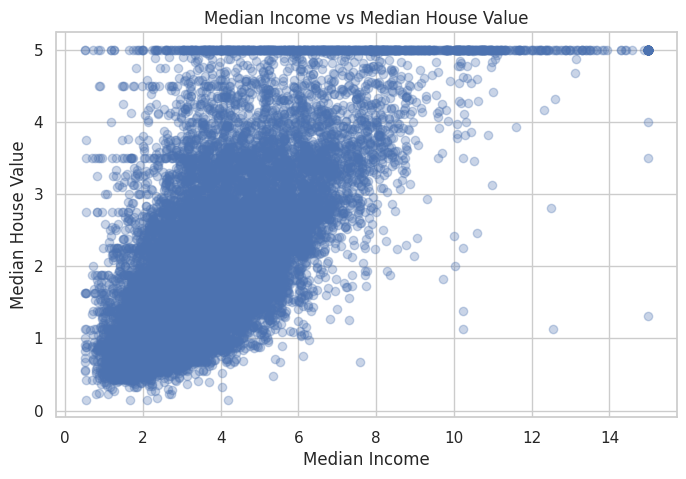

In [10]:
# Scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df['MedInc'],
    df['MedHouseVal'],
    alpha=0.3
)

plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.title('Median Income vs Median House Value')

plt.show()

In [11]:
# Reusable function for plot
def plot_scatter(data, features, target):
    for feature in features:

        plt.figure(figsize=(7, 4))

        plt.scatter(
            data[feature],
            data[target],
            alpha=0.3
        )

        plt.xlabel(feature)
        plt.ylabel(target)
        plt.title(f'{feature} vs {target}')

        plt.tight_layout()
        plt.show()

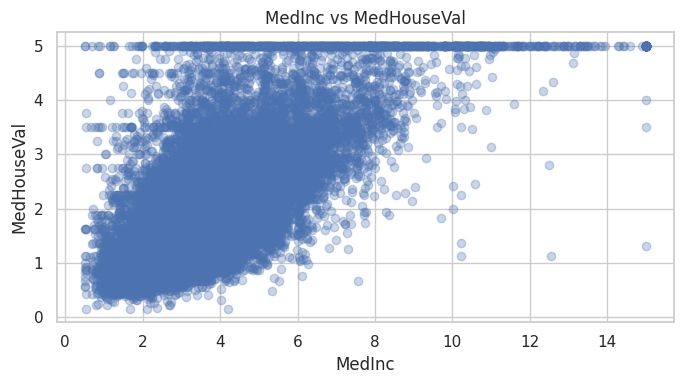

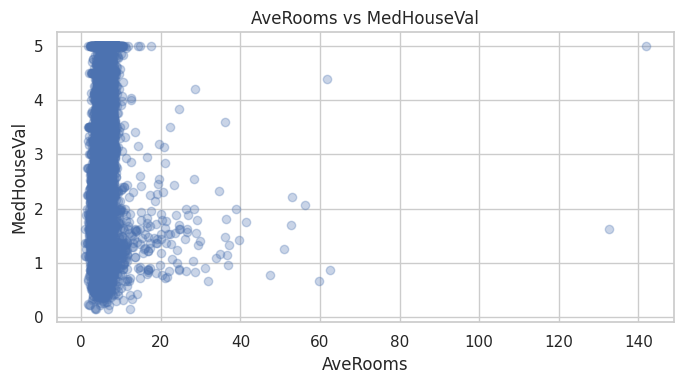

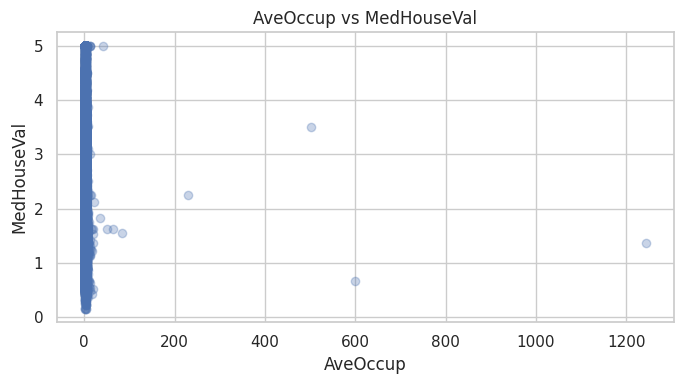

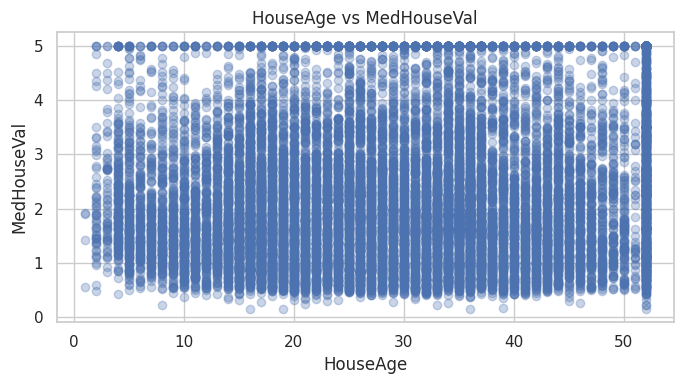

In [12]:
#Apply function

features = [
    'MedInc',
    'AveRooms',
    'AveOccup',
    'HouseAge'
]

plot_scatter(df, features, 'MedHouseVal')

In [13]:
# independent and dependent variables
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

In [14]:
#Test and train 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


In [15]:
#Regression model

model = LinearRegression()

In [16]:
# Trainn model

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [17]:
# Model evaluation

y_pred = model.predict(X_test)

In [18]:
# Evaluation metrics for performance

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate R-squared
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("RMSE:", rmse)
print("R-squared:", r2)


Model Evaluation Results
------------------------
RMSE: 0.745581383012776
R-squared: 0.5757877060324512


In [19]:
# Model prediction of new data

# Create new housing data
new_data = pd.DataFrame({
    'MedInc': [3],
    'HouseAge': [30],
    'AveRooms': [6],
    'AveBedrms': [1],
    'Population': [1500],
    'AveOccup': [3],
    'Latitude': [34],
    'Longitude': [-118]
})

# Predict median house value
prediction = model.predict(new_data)

# Convert prediction into dollars
predicted_value = prediction[0] * 100000

print("Predicted Median House Value:")
print(f"${predicted_value:,.2f}")

Predicted Median House Value:
$154,866.33
